In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud

In [2]:
review_df=pd.read_csv("../data/IMDB Dataset.csv")

In [3]:
review_df.head(5)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
review_df.shape

(50000, 2)

In [5]:
review_df.duplicated().sum()

np.int64(418)

In [6]:
# Drop the duplicate rows
review_df.drop_duplicates(inplace=True)

# Verify they are gone and check the new shape
print(review_df.shape)

(49582, 2)


In [7]:
review_df.isna().sum()

review       0
sentiment    0
dtype: int64

In [8]:
#Check the balance of positive and negative reviews
print(review_df['sentiment'].value_counts())

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [9]:
review_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49582 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     49582 non-null  object
 1   sentiment  49582 non-null  object
dtypes: object(2)
memory usage: 1.1+ MB


In [10]:
review_df[review_df["sentiment"]=="positive"]["review"].iloc[0]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

In [11]:
review_df[review_df["sentiment"]=="negative"]["review"].iloc[0]

"Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents are divorcing & arguing like in real life. And then we have Jake with his closet which totally ruins all the film! I expected to see a BOOGEYMAN similar movie, and instead i watched a drama with some meaningless thriller spots.<br /><br />3 out of 10 just for the well playing parents & descent dialogs. As for the shots with Jake: just ignore them."

In [12]:
# Character length
review_df["char_length"] = review_df["review"].str.len()

# Word length
review_df["word_length"] = review_df["review"].str.split().str.len()

# Summary statistics
review_df[["char_length", "word_length"]].describe()

,char_length,word_length
count,49582.000000,49582.000000
mean,1310.568230,231.350167
std,990.762238,171.542020
min,32.000000,4.000000
25%,699.000000,126.000000
50%,971.000000,173.000000
75%,1592.000000,281.000000
max,13704.000000,2470.000000


In [13]:
review_df["sentiment"].value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

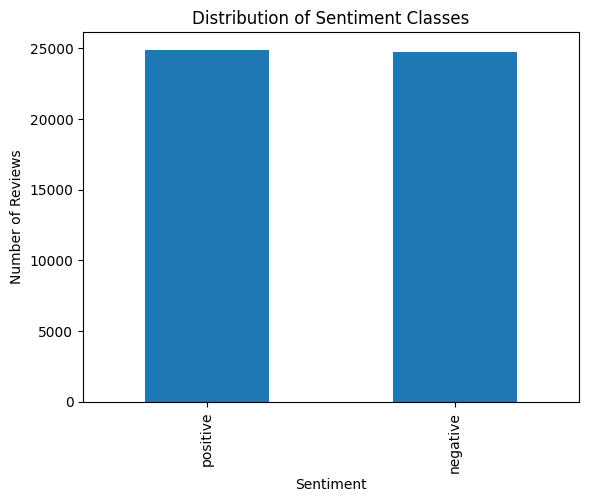

In [14]:
review_df["sentiment"].value_counts().plot(
    kind="bar"
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

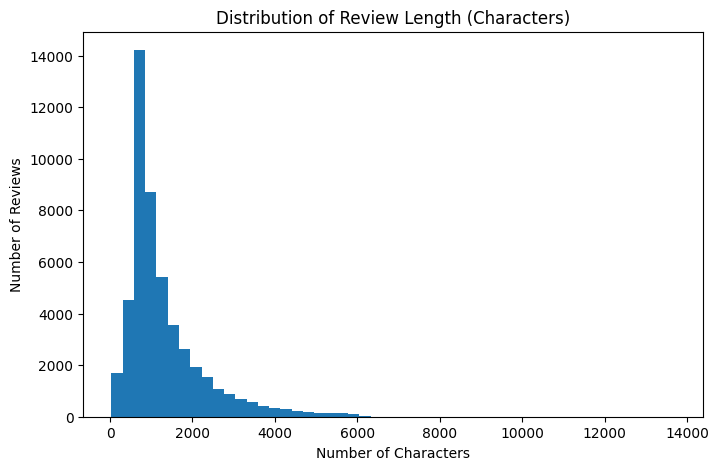

In [15]:
plt.figure(figsize=(8,5))

review_df["char_length"].plot(
    kind="hist",
    bins=50
)

plt.title("Distribution of Review Length (Characters)")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")

plt.show()

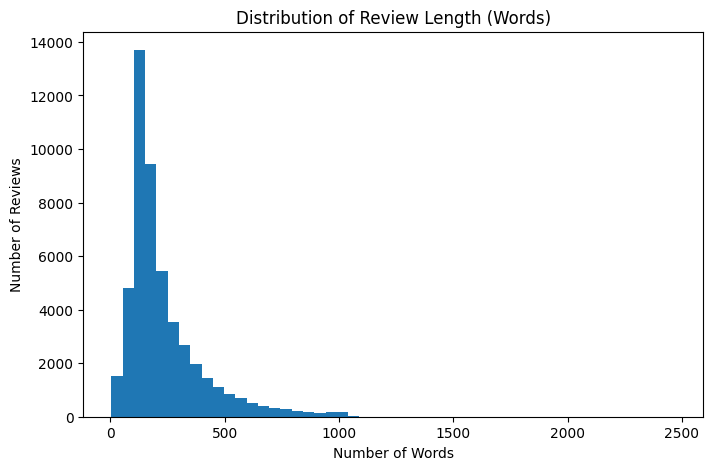

In [16]:
plt.figure(figsize=(8,5))

review_df["word_length"].plot(
    kind="hist",
    bins=50
)

plt.title("Distribution of Review Length (Words)")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [17]:
positive_text = " ".join(
    review_df[review_df["sentiment"] == "positive"]["review"]
).lower()

positive_words = positive_text.split()
positive_counts = Counter(positive_words)
positive_counts.most_common(20)

positive_df = pd.DataFrame(
    positive_counts.most_common(20),
    columns=["Word", "Frequency"]
)

positive_df

,Word,Frequency
0,the,325111
1,and,170782
2,a,160440
3,of,150236
4,to,129177
5,is,108654
6,in,95343
7,i,66516
8,it,64530
9,this,63902


In [18]:
negative_text = " ".join(
    review_df[review_df["sentiment"] == "negative"]["review"]
).lower()

negative_words = negative_text.split()
negative_counts = Counter(negative_words)
negative_counts.most_common(20)

negative_df = pd.DataFrame(
    negative_counts.most_common(20),
    columns=["Word", "Frequency"]
)

negative_df

,Word,Frequency
0,the,308870
1,a,153968
2,and,140596
3,of,134372
4,to,133422
5,is,94834
6,in,83144
7,i,73877
8,this,73496
9,that,65536


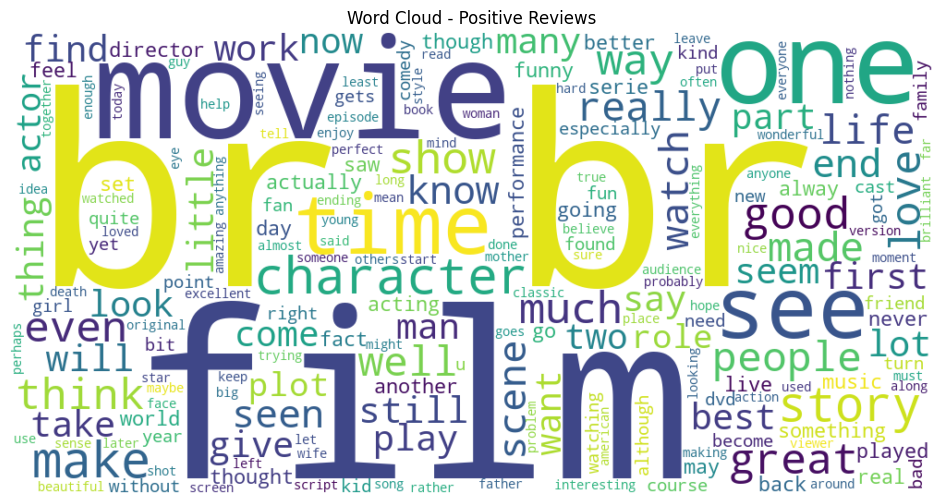

In [19]:
positive_cloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(12,6))
plt.imshow(positive_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Reviews")
plt.show()

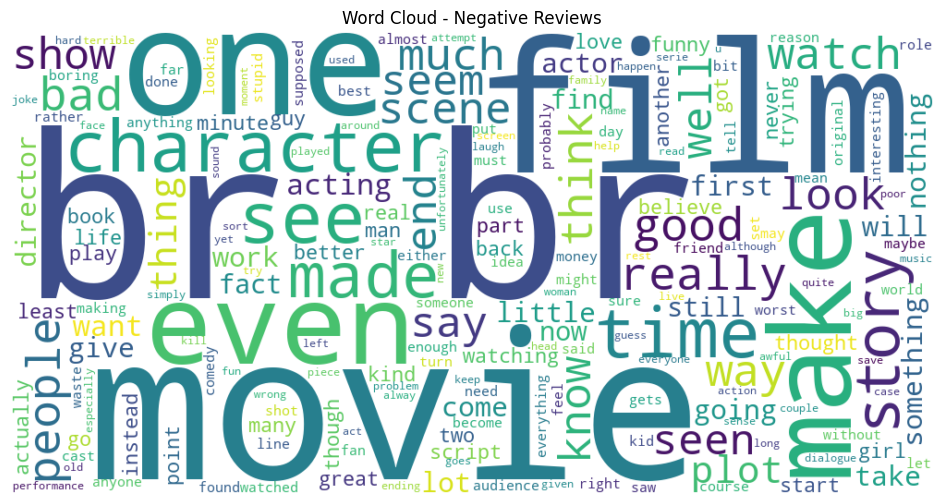

In [21]:
negative_cloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(12,6))
plt.imshow(negative_cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Negative Reviews")
plt.show()